In [ ]:

# IPL WINNER PREDICTION PROJECT


import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
from xgboost import XGBClassifier
import joblib


In [ ]:

#  Load Data

def load_data(filepath):
    df = pd.read_csv(filepath)
    return df

In [ ]:


#  Clean Data

def clean_data(df):
    df = df.drop_duplicates()
    df = df.dropna(subset=['home_team', 'away_team', 'toss_won', 'decision', 'winner'])
    df = df[df['toss_won'] != 'no toss'].copy()

    df['start_date'] = pd.to_datetime(df['start_date'], errors='coerce', utc=True)
    df['end_date'] = pd.to_datetime(df['end_date'], errors='coerce', utc=True)
    df = df.dropna(subset=['start_date', 'end_date'])

    # Extract scores
    for col in ['1st_inning_score', '2nd_inning_score']:
        if col in df.columns:
            df[col] = df[col].astype(str).str.split('/').str[0]
            df[col] = pd.to_numeric(df[col], errors='coerce')

    df = df.dropna(subset=['1st_inning_score', '2nd_inning_score'])
    df = df.reset_index(drop=True)
    return df
# 180/3


In [ ]:

#  One-Hot Encoding

def one_hot_encode(df):
    categorical_cols = ['home_team', 'away_team', 'toss_won', 'decision', 'venue_name']
    df_encoded = pd.get_dummies(df, columns=categorical_cols, drop_first=True)
    return df_encoded

In [ ]:

#  Model Training

def train_model(df_encoded, df_original):
    # Drop non-numeric columns before training
    X = df_encoded.select_dtypes(exclude=['object']).drop(columns=['start_date', 'end_date'], errors='ignore')
    y, labels = pd.factorize(df_original['winner'])

    X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

    model = XGBClassifier(use_label_encoder=False, eval_metric='mlogloss')
    model.fit(X_train, y_train)

    y_pred = model.predict(X_test)

    print(" Model Trained Successfully!")
    print("Accuracy:", accuracy_score(y_test, y_pred))
    print("\nClassification Report:\n", classification_report(y_test, y_pred))

    cm = confusion_matrix(y_test, y_pred)
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues')
    plt.title("Confusion Matrix")
    plt.show()

    return model, X.columns, labels




In [ ]:
'''import lightgbm as lgb
#  Model Training with LightGBM
def train_model(df_encoded, df_original):
    # Drop non-numeric columns before training
    X = df_encoded.select_dtypes(exclude=['object']).drop(columns=['start_date', 'end_date'], errors='ignore')

    # Target labels
    y, labels = pd.factorize(df_original['winner'])

    # Split data
    X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

    # Create LightGBM Classifier
    model = lgb.LGBMClassifier(
        objective='multiclass',
        num_class=len(labels),
        n_estimators=500,      # number of boosting rounds
        learning_rate=0.05,
        random_state=42,
        n_jobs=-1
    )

    # Train the model
    model.fit(X_train, y_train)

    # Predict
    y_pred = model.predict(X_test)

    # Evaluation
    print(" Model Trained Successfully!")
    print("Accuracy:", accuracy_score(y_test, y_pred))
    print("\nClassification Report:\n", classification_report(y_test, y_pred))

    # Confusion Matrix
    cm = confusion_matrix(y_test, y_pred)
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues')
    plt.title("Confusion Matrix")
    plt.show()

    return model, X.columns, labels'''

'import lightgbm as lgb\n#  Model Training with LightGBM\ndef train_model(df_encoded, df_original):\n    # Drop non-numeric columns before training\n    X = df_encoded.select_dtypes(exclude=[\'object\']).drop(columns=[\'start_date\', \'end_date\'], errors=\'ignore\')\n\n    # Target labels\n    y, labels = pd.factorize(df_original[\'winner\'])\n\n    # Split data\n    X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)\n\n    # Create LightGBM Classifier\n    model = lgb.LGBMClassifier(\n        objective=\'multiclass\',\n        num_class=len(labels),\n        n_estimators=500,      # number of boosting rounds\n        learning_rate=0.05,\n        random_state=42,\n        n_jobs=-1\n    )\n\n    # Train the model\n    model.fit(X_train, y_train)\n\n    # Predict\n    y_pred = model.predict(X_test)\n\n    # Evaluation\n    print(" Model Trained Successfully!")\n    print("Accuracy:", accuracy_score(y_test, y_pred))\n    print("\nClassification Rep

In [ ]:

#  Save Model

def save_model(model, feature_columns, winner_labels, df, model_path='ipl_winner_model_numinput.pkl'):
    data = {
        'model': model,
        'features': feature_columns,
        'winner_labels': winner_labels,
        'teams': sorted(df['home_team'].unique()),
        'venues': sorted(df['venue_name'].unique()),
        'decisions': sorted(df['decision'].unique())
    }
    joblib.dump(data, model_path)
    print(f" Model saved to {model_path}")


In [ ]:

#  Numeric Input Prediction System

def predict_match(model_path='ipl_winner_model_numinput.pkl'):
    data = joblib.load(model_path)
    model = data['model']
    features = data['features']
    winner_labels = data['winner_labels']
    teams = data['teams']
    venues = data['venues']
    decisions = data['decisions']

    print("\n ENTER MATCH DETAILS USING NUMERIC CODES")

    # TEAM options
    print("\n TEAMS:")
    for i, t in enumerate(teams):
        print(f"{i}: {t}")

    print("\n DECISIONS:")
    for i, d in enumerate(decisions):
        print(f"{i}: {d}")

    print("\n VENUES:")
    for i, v in enumerate(venues):
        print(f"{i}: {v}")

    # User numeric input
    home_team = teams[int(input("\nEnter code for HOME TEAM: "))]
    away_team = teams[int(input("Enter code for AWAY TEAM: "))]
    toss_won = teams[int(input("Enter code for TOSS WINNER: "))]
    decision = decisions[int(input("Enter code for DECISION: "))]
    venue = venues[int(input("Enter code for VENUE: "))]
    first_inning_score = float(input("Enter 1st INNING SCORE: "))

    # Create one-row DataFrame
    input_dict = {
        '1st_inning_score': [first_inning_score],
        'home_team': [home_team],
        'away_team': [away_team],
        'toss_won': [toss_won],
        'decision': [decision],
        'venue_name': [venue]
    }

    input_df = pd.DataFrame(input_dict)
    input_encoded = pd.get_dummies(input_df)

    # Align with training columns
    for col in features:
        if col not in input_encoded.columns:
            input_encoded[col] = 0
    input_encoded = input_encoded[features]

    # Predict
    pred = model.predict(input_encoded)[0]
    print("\n🎯 Predicted Match Winner:", winner_labels[pred])



/usr/local/lib/python3.12/dist-packages/xgboost/training.py:200: UserWarning: [13:45:28] WARNING: /__w/xgboost/xgboost/src/learner.cc:782: 
Parameters: { "use_label_encoder" } are not used.

  bst.update(dtrain, iteration=i, fobj=obj)


 Model Trained Successfully!
Accuracy: 0.7941176470588235

Classification Report:
               precision    recall  f1-score   support

           0       0.75      0.75      0.75         4
           1       0.92      0.96      0.94        23
           2       0.67      0.80      0.73         5
           3       0.87      0.52      0.65        25
           4       0.87      0.87      0.87        23
           5       0.68      0.89      0.77        19
           6       0.78      0.90      0.84        20
           7       0.74      0.77      0.76        22
           8       1.00      0.33      0.50         3
           9       0.81      0.90      0.85        29
          10       0.71      0.75      0.73        20
          11       0.67      0.67      0.67         3
          12       1.00      0.33      0.50         3
          13       1.00      0.67      0.80         3
          14       1.00      0.50      0.67         2

    accuracy                           0.79       2

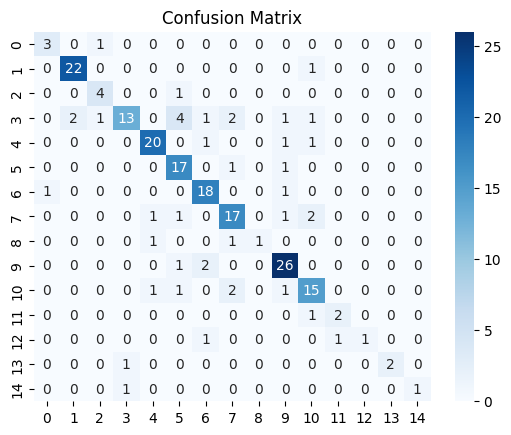

 Model saved to ipl_winner_model_numinput.pkl

 ENTER MATCH DETAILS USING NUMERIC CODES

 TEAMS:
0: CSK
1: DC
2: GL
3: GT
4: KKR
5: KXIP
6: Kochi
7: LSG
8: MI
9: PBKS
10: PWI
11: RCB
12: RPS
13: RR
14: SRH

 DECISIONS:
0: BAT FIRST
1: BOWL FIRST

 VENUES:
0: Arun Jaitley Stadium, Delhi
1: Barabati Stadium, Cuttack
2: Barsapara Cricket Stadium, Guwahati
3: Bharat Ratna Shri Atal Bihari Vajpayee Ekana Cricket Stadium, Lucknow
4: Brabourne Stadium, Mumbai
5: Buffalo Park, East London
6: Diamond Oval, Kimberley
7: Dr DY Patil Sports Academy, Mumbai
8: Dr DY Patil Sports Academy, Navi Mumbai
9: Dr. Y.S. Rajasekhara Reddy ACA-VDCA Cricket Stadium, Visakhapatnam
10: Dubai International Cricket Stadium
11: Eden Gardens, Kolkata
12: Green Park, Kanpur
13: Himachal Pradesh Cricket Association Stadium, Dharamsala
14: Holkar Cricket Stadium, Indore
15: JSCA International Stadium Complex, Ranchi
16: Kingsmead, Durban
17: M.Chinnaswamy Stadium, Bengaluru
18: MA Chidambaram Stadium, Chepauk, Chennai


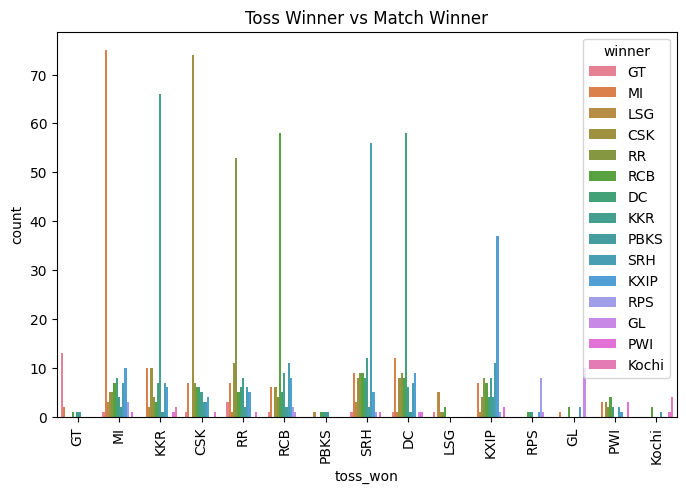


Toss Winning Team Winning Probability:
toss_won
GT       0.722222
GL       0.666667
CSK      0.632479
RPS      0.615385
MI       0.572519
KKR      0.554622
RCB      0.513274
Kochi    0.500000
LSG      0.500000
RR       0.490741
DC       0.475410
SRH      0.451613
KXIP     0.393617
PBKS     0.200000
PWI      0.150000
Name: winner, dtype: float64


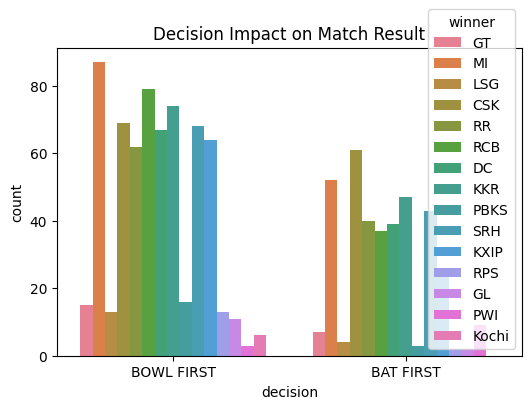


Home Advantage - Win Rate: 0.53


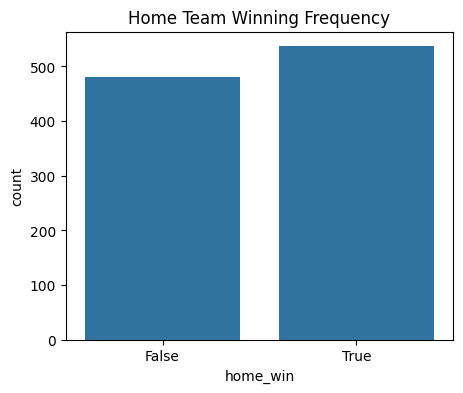

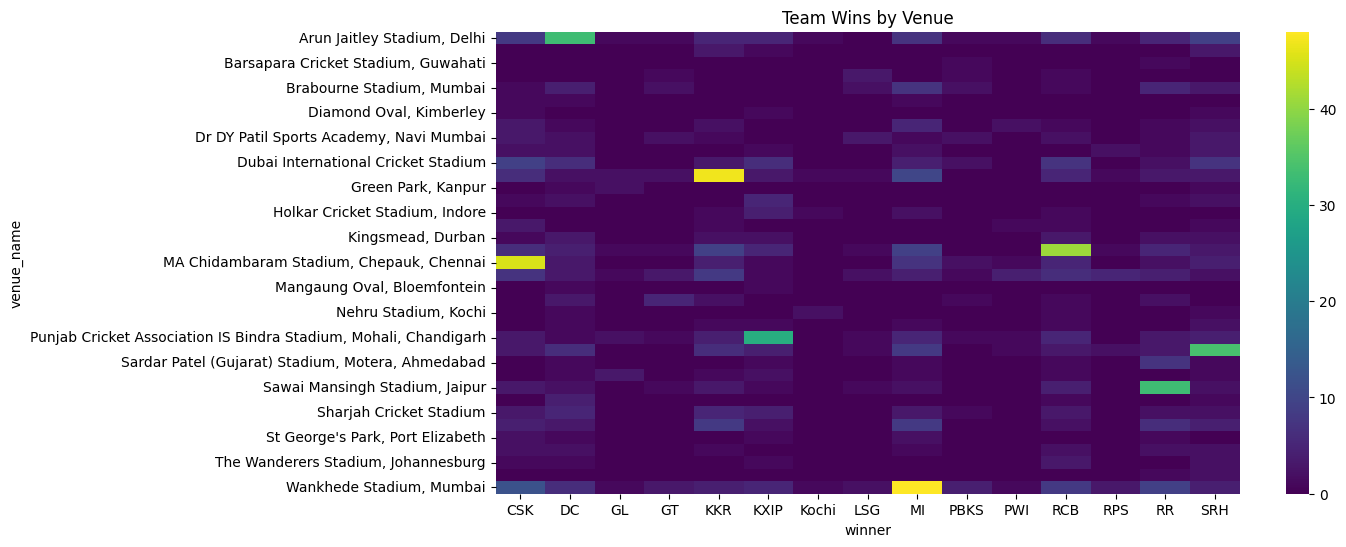

In [ ]:

#  Main Execution

if __name__ == "__main__":
    data_path = '/content/Cricket_data.csv'
    df = load_data(data_path)
    df = clean_data(df)
    df_encoded = one_hot_encode(df)

    model, feature_columns, winner_labels = train_model(df_encoded, df)
    save_model(model, feature_columns, winner_labels, df)

    # Run prediction with numeric input
    predict_match('ipl_winner_model_numinput.pkl')



    import seaborn as sns
import matplotlib.pyplot as plt

#  Toss Result vs Match Outcome
plt.figure(figsize=(8,5))
sns.countplot(x='toss_won', hue='winner', data=df)
plt.title('Toss Winner vs Match Winner')
plt.xticks(rotation=90)
plt.show()

toss_impact = df.groupby('toss_won')['winner'].apply(lambda x: (x == x.name).mean())
print("\nToss Winning Team Winning Probability:")
print(toss_impact.sort_values(ascending=False))

#  Decision (Bat/Field) vs Winning
plt.figure(figsize=(6,4))
sns.countplot(x='decision', hue='winner', data=df)
plt.title('Decision Impact on Match Result')
plt.show()

#  Home Advantage
df['home_win'] = df['winner'] == df['home_team']
home_advantage = df['home_win'].mean()
print(f"\nHome Advantage - Win Rate: {home_advantage:.2f}")

plt.figure(figsize=(5,4))
sns.countplot(x='home_win', data=df)
plt.title('Home Team Winning Frequency')
plt.show()

#  Venue-wise Win Distribution
venue_wins = df.groupby('venue_name')['winner'].value_counts().unstack().fillna(0)
plt.figure(figsize=(12,6))
sns.heatmap(venue_wins, cmap='viridis')
plt.title('Team Wins by Venue')
plt.show()



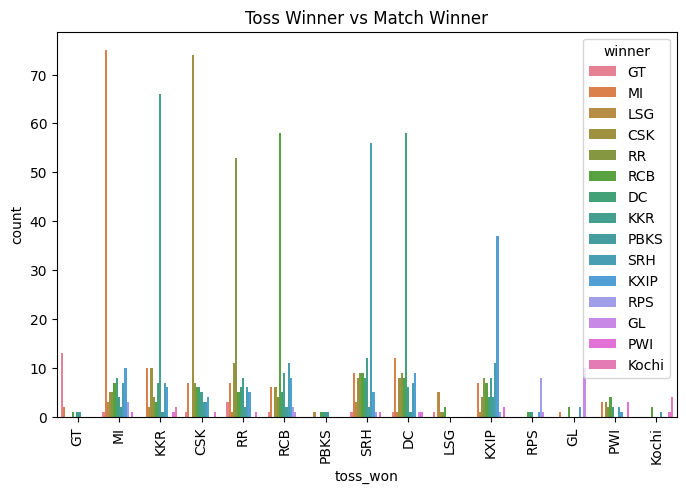


Toss Winning Team Winning Probability:
toss_won
GT       0.722222
GL       0.666667
CSK      0.632479
RPS      0.615385
MI       0.572519
KKR      0.554622
RCB      0.513274
Kochi    0.500000
LSG      0.500000
RR       0.490741
DC       0.475410
SRH      0.451613
KXIP     0.393617
PBKS     0.200000
PWI      0.150000
Name: winner, dtype: float64


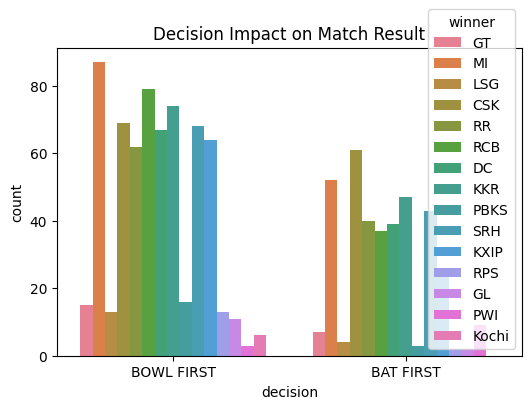


Home Advantage - Win Rate: 0.53


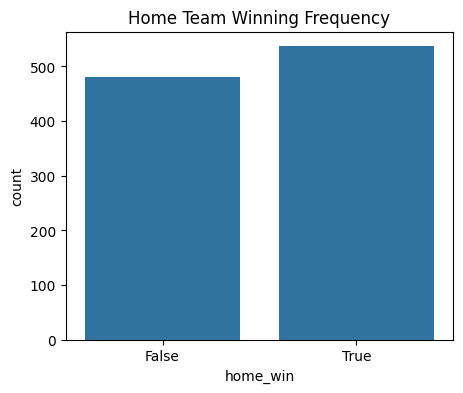

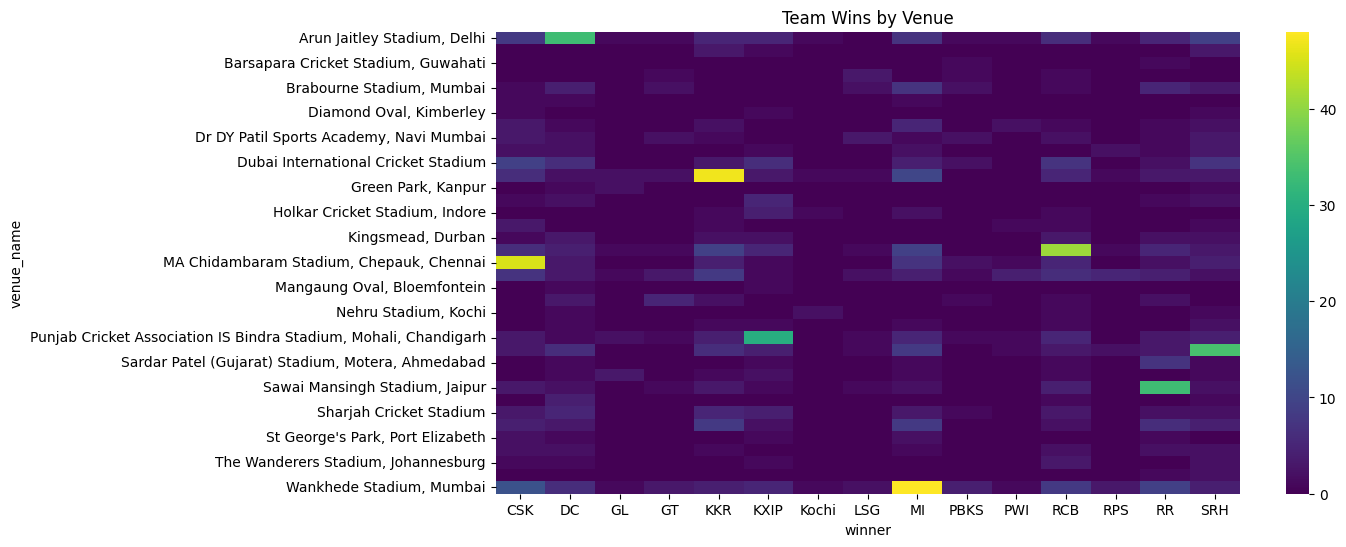

In [ ]:
import seaborn as sns
import matplotlib.pyplot as plt

#  Toss Result vs Match Outcome
plt.figure(figsize=(8,5))
sns.countplot(x='toss_won', hue='winner', data=df)
plt.title('Toss Winner vs Match Winner')
plt.xticks(rotation=90)
plt.show()

toss_impact = df.groupby('toss_won')['winner'].apply(lambda x: (x == x.name).mean())
print("\nToss Winning Team Winning Probability:")
print(toss_impact.sort_values(ascending=False))

#  Decision (Bat/Field) vs Winning
plt.figure(figsize=(6,4))
sns.countplot(x='decision', hue='winner', data=df)
plt.title('Decision Impact on Match Result')
plt.show()

#  Home Advantage
df['home_win'] = df['winner'] == df['home_team']
home_advantage = df['home_win'].mean()
print(f"\nHome Advantage - Win Rate: {home_advantage:.2f}")

plt.figure(figsize=(5,4))
sns.countplot(x='home_win', data=df)
plt.title('Home Team Winning Frequency')
plt.show()

#  Venue-wise Win Distribution
venue_wins = df.groupby('venue_name')['winner'].value_counts().unstack().fillna(0)
plt.figure(figsize=(12,6))
sns.heatmap(venue_wins, cmap='viridis')
plt.title('Team Wins by Venue')
plt.show()


<Figure size 1400x600 with 0 Axes>

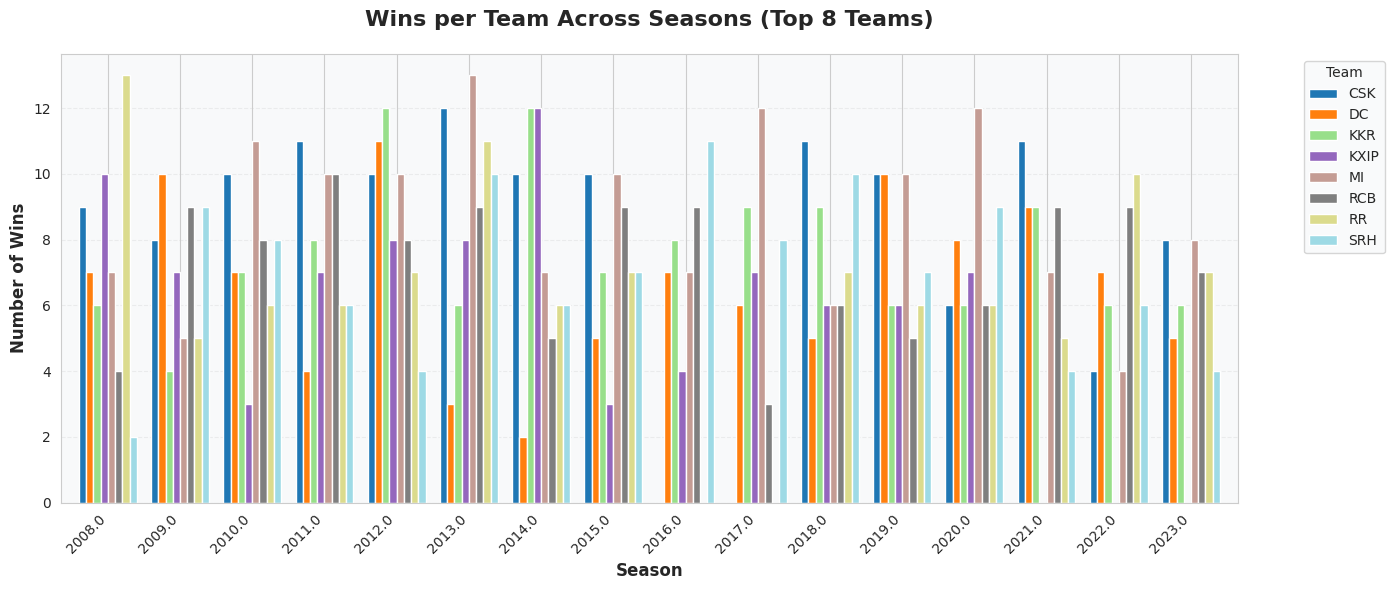

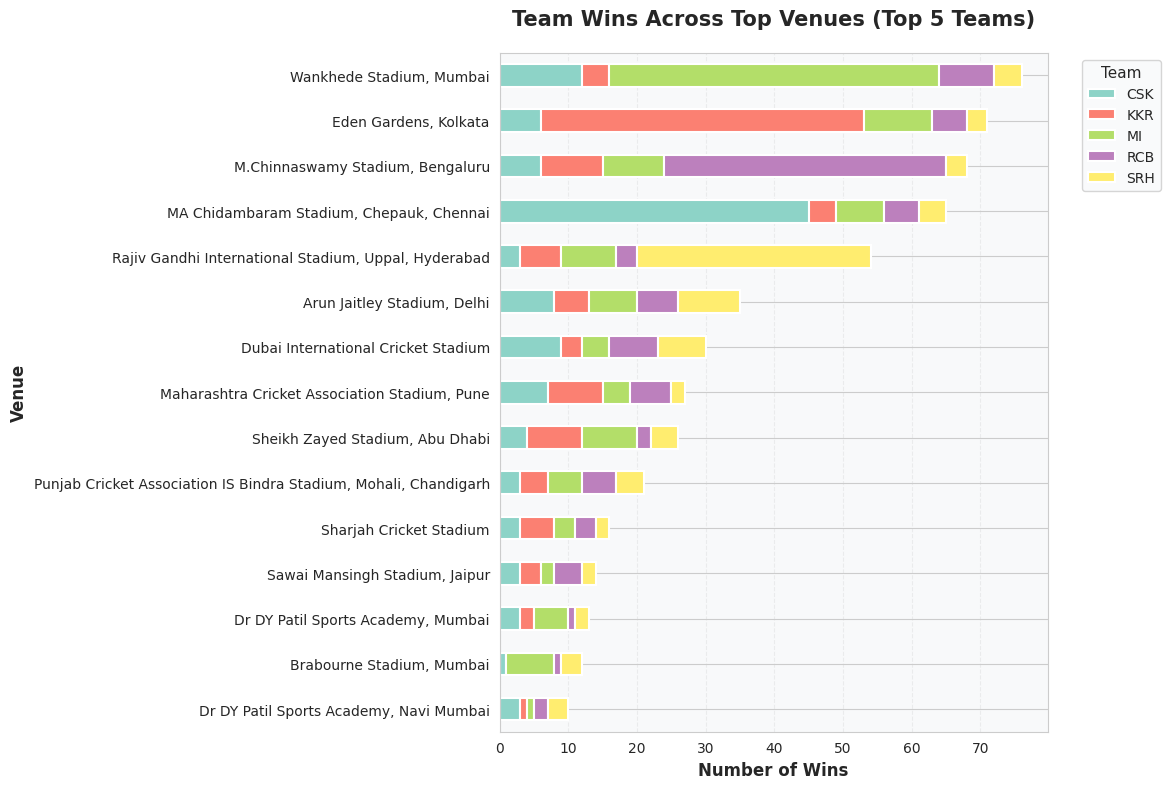

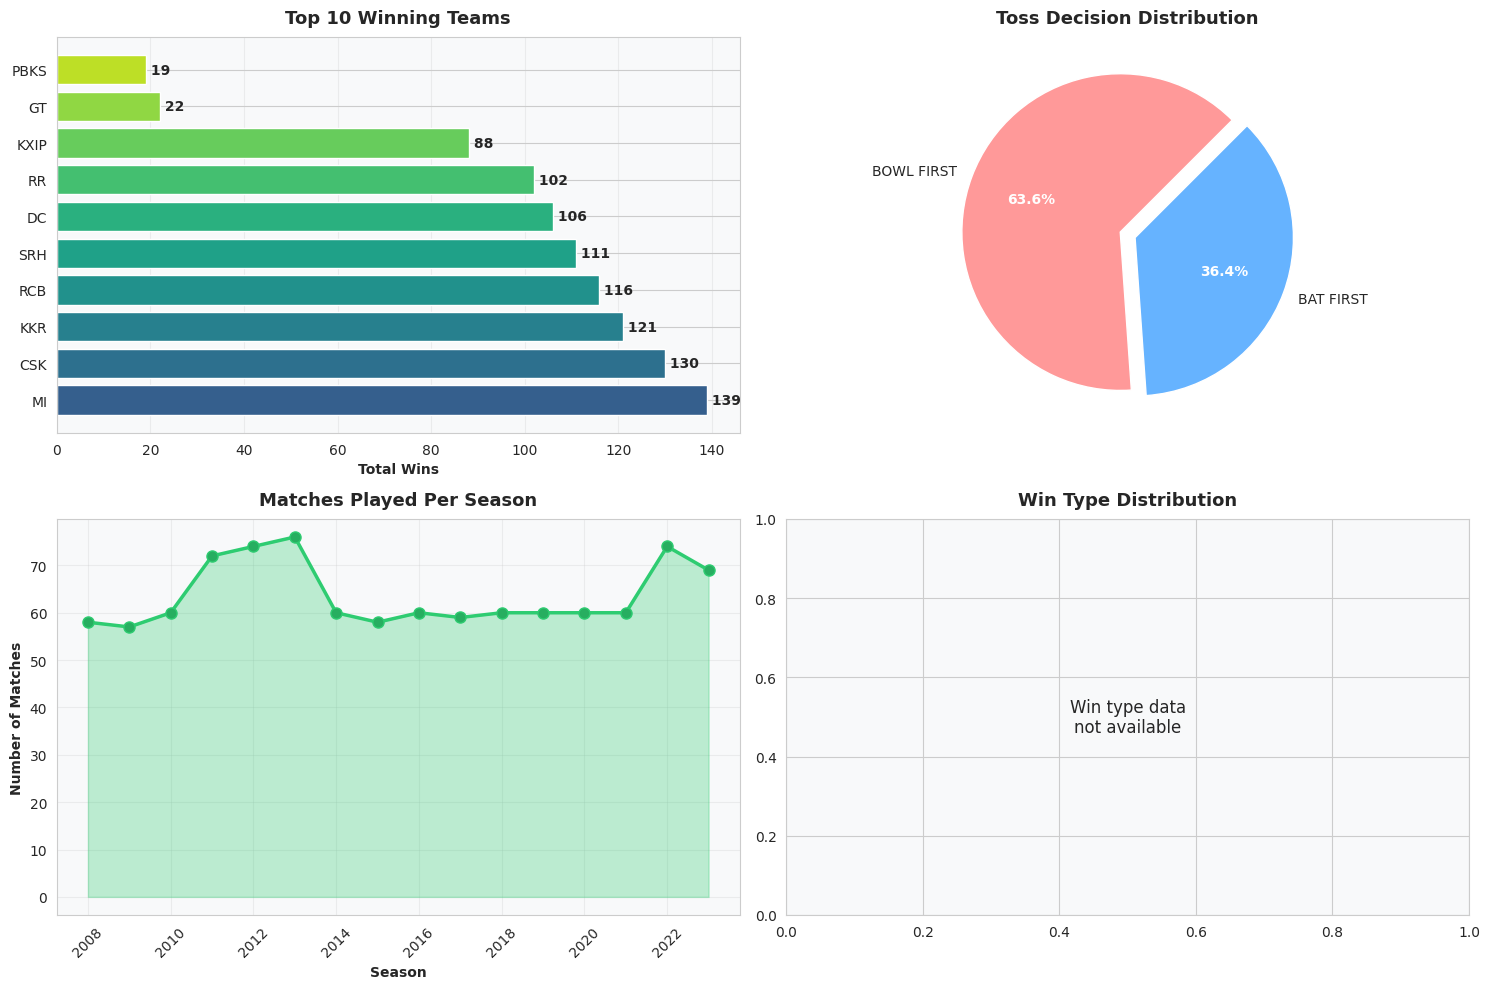


 All visualizations created successfully!


In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np


sns.set_style("whitegrid")
plt.rcParams['figure.facecolor'] = 'white'
plt.rcParams['axes.facecolor'] = '#f8f9fa'




#  SEASON-WISE WIN TREND

plt.figure(figsize=(14, 6))

# Count wins per season per team
season_wins = df.groupby(['season', 'winner']).size().reset_index(name='wins')

# Get top 8 teams by total wins
top_teams = df['winner'].value_counts().head(8).index

# Filter for top teams only
season_wins_filtered = season_wins[season_wins['winner'].isin(top_teams)]

# Create pivot table for better visualization
pivot_data = season_wins_filtered.pivot(index='season', columns='winner', values='wins').fillna(0)

# Plot stacked bar chart
pivot_data.plot(kind='bar', stacked=False, figsize=(14, 6),
                colormap='tab20', width=0.8, edgecolor='white')

plt.title('Wins per Team Across Seasons (Top 8 Teams)', fontsize=16, fontweight='bold', pad=20)
plt.xlabel('Season', fontsize=12, fontweight='bold')
plt.ylabel('Number of Wins', fontsize=12, fontweight='bold')
plt.legend(title='Team', bbox_to_anchor=(1.05, 1), loc='upper left', frameon=True)
plt.xticks(rotation=45, ha='right')
plt.grid(axis='y', alpha=0.3, linestyle='--')
plt.tight_layout()
plt.show()


#  VENUE PERFORMANCE (IMPROVED)

# Get top 15 venues by match count
top_venues = df['venue_name'].value_counts().head(15).index
df_top_venues = df[df['venue_name'].isin(top_venues)]

# Count wins per venue per team
venue_wins = df_top_venues.groupby(['venue_name', 'winner']).size().reset_index(name='wins')

# Get top 5 teams
top_5_teams = df['winner'].value_counts().head(5).index
venue_wins_filtered = venue_wins[venue_wins['winner'].isin(top_5_teams)]

# Create pivot table
pivot_venue = venue_wins_filtered.pivot(index='venue_name', columns='winner', values='wins').fillna(0)

# Sort by total wins
pivot_venue['total'] = pivot_venue.sum(axis=1)
pivot_venue = pivot_venue.sort_values('total', ascending=True).drop('total', axis=1)

# Plot horizontal stacked bar chart
fig, ax = plt.subplots(figsize=(12, 8))
pivot_venue.plot(kind='barh', stacked=True, ax=ax,
                 colormap='Set3', edgecolor='white', linewidth=1.5)

ax.set_title('Team Wins Across Top Venues (Top 5 Teams)',
             fontsize=15, fontweight='bold', pad=20)
ax.set_xlabel('Number of Wins', fontsize=12, fontweight='bold')
ax.set_ylabel('Venue', fontsize=12, fontweight='bold')
ax.legend(title='Team', bbox_to_anchor=(1.05, 1), loc='upper left',
          frameon=True, title_fontsize=11)
ax.grid(axis='x', alpha=0.3, linestyle='--')

plt.tight_layout()
plt.show()


#  BONUS: MATCH OUTCOMES OVERVIEW

fig, axes = plt.subplots(2, 2, figsize=(15, 10))

# Top winning teams
ax = axes[0, 0]
top_10_winners = df['winner'].value_counts().head(10)
bars = ax.barh(range(len(top_10_winners)), top_10_winners.values,
               color=plt.cm.viridis(np.linspace(0.3, 0.9, len(top_10_winners))))
ax.set_yticks(range(len(top_10_winners)))
ax.set_yticklabels(top_10_winners.index)
ax.set_xlabel('Total Wins', fontweight='bold')
ax.set_title('Top 10 Winning Teams', fontsize=13, fontweight='bold', pad=10)
ax.grid(axis='x', alpha=0.3)
for i, (bar, val) in enumerate(zip(bars, top_10_winners.values)):
    ax.text(val, i, f' {val}', va='center', fontweight='bold')

# Toss decision distribution
ax = axes[0, 1]
toss_counts = df['decision'].value_counts()
colors_toss = ['#ff9999', '#66b3ff']
wedges, texts, autotexts = ax.pie(toss_counts.values, labels=toss_counts.index,
                                    autopct='%1.1f%%', startangle=45,
                                    colors=colors_toss, explode=(0.05, 0.05))
ax.set_title('Toss Decision Distribution', fontsize=13, fontweight='bold', pad=10)
for autotext in autotexts:
    autotext.set_color('white')
    autotext.set_fontweight('bold')

# Matches per season
ax = axes[1, 0]
season_counts = df['season'].value_counts().sort_index()
ax.plot(season_counts.index, season_counts.values, marker='o',
        linewidth=2.5, markersize=8, color='#2ecc71', markerfacecolor='#27ae60')
ax.fill_between(season_counts.index, season_counts.values, alpha=0.3, color='#2ecc71')
ax.set_xlabel('Season', fontweight='bold')
ax.set_ylabel('Number of Matches', fontweight='bold')
ax.set_title('Matches Played Per Season', fontsize=13, fontweight='bold', pad=10)
ax.grid(True, alpha=0.3)
ax.tick_params(axis='x', rotation=45)

# Win by margin type (if 'win_by_runs' and 'win_by_wickets' exist)
ax = axes[1, 1]
if 'win_by_runs' in df.columns and 'win_by_wickets' in df.columns:
    win_types = ['By Runs', 'By Wickets']
    win_counts = [
        df[df['win_by_runs'] > 0].shape[0],
        df[df['win_by_wickets'] > 0].shape[0]
    ]
    colors_win = ['#ff6b6b', '#4ecdc4']
    bars = ax.bar(win_types, win_counts, color=colors_win, edgecolor='white', linewidth=2)
    for bar, count in zip(bars, win_counts):
        height = bar.get_height()
        ax.text(bar.get_x() + bar.get_width()/2., height,
                f'{count}', ha='center', va='bottom', fontweight='bold', fontsize=11)
    ax.set_ylabel('Number of Matches', fontweight='bold')
    ax.set_title('Win Type Distribution', fontsize=13, fontweight='bold', pad=10)
    ax.grid(axis='y', alpha=0.3)
else:
    ax.text(0.5, 0.5, 'Win type data\nnot available',
            ha='center', va='center', fontsize=12, transform=ax.transAxes)
    ax.set_title('Win Type Distribution', fontsize=13, fontweight='bold', pad=10)

plt.tight_layout()
plt.show()

print("\n All visualizations created successfully!")

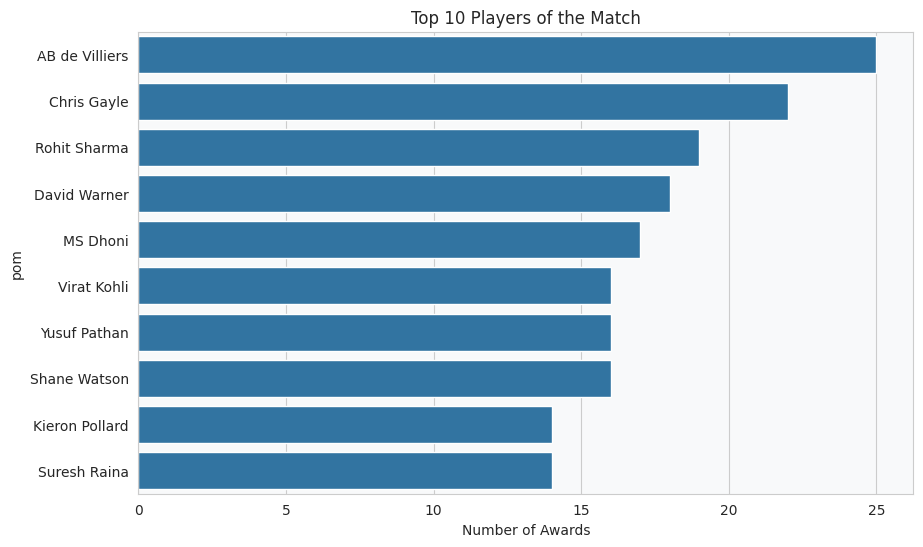

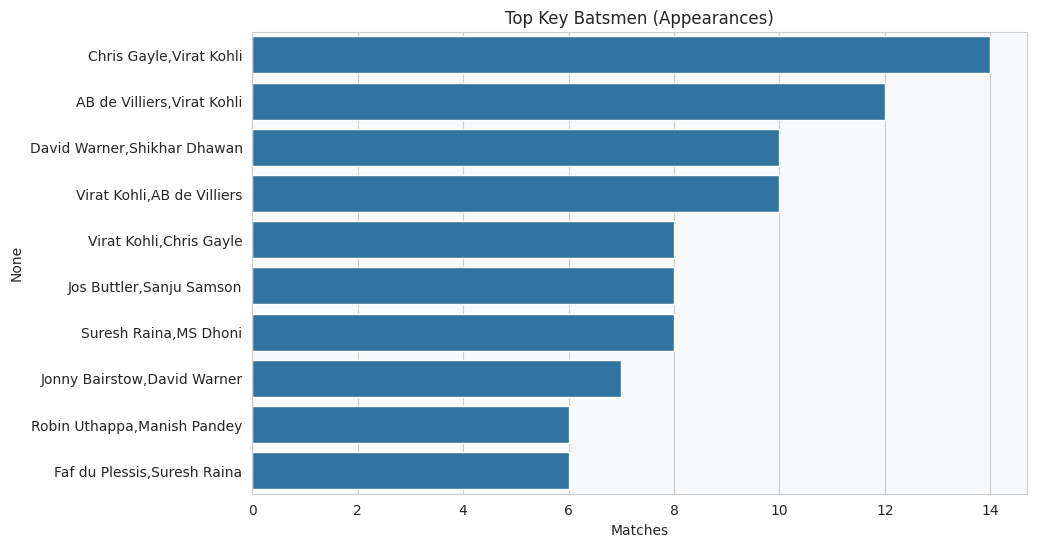

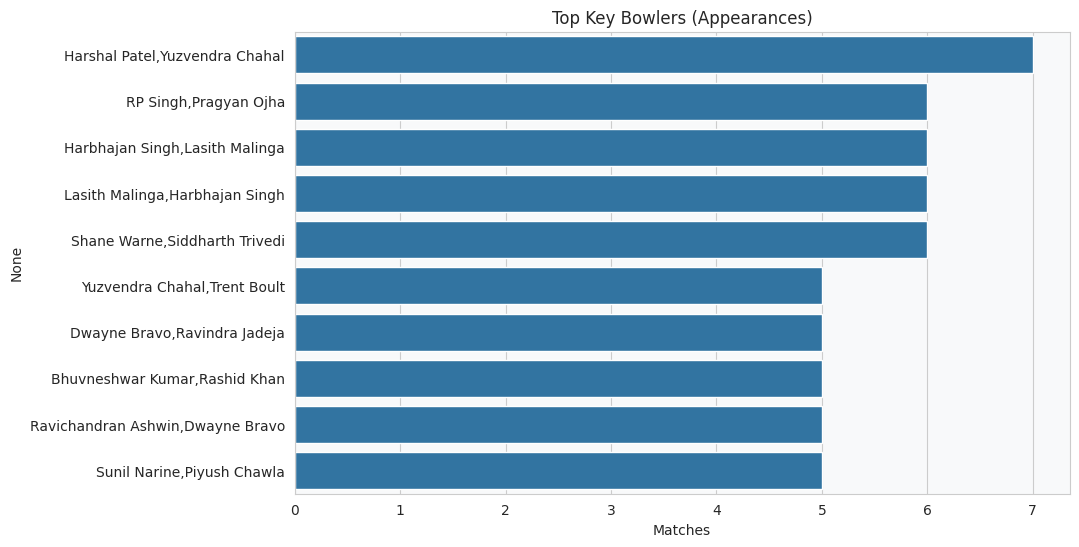


Top Match-Winning Players:
pom
AB de Villiers     25.0
Chris Gayle        22.0
Rohit Sharma       19.0
David Warner       18.0
MS Dhoni           17.0
Virat Kohli        16.0
Shane Watson       16.0
Yusuf Pathan       16.0
Ravindra Jadeja    14.0
Suresh Raina       14.0
dtype: float64


In [ ]:
#  Player of the Match Frequency
plt.figure(figsize=(10,6))
pom_counts = df['pom'].value_counts().head(10)
sns.barplot(x=pom_counts.values, y=pom_counts.index)
plt.title('Top 10 Players of the Match')
plt.xlabel('Number of Awards')
plt.show()

#  Key Batsmen Performance Impact
key_batsmen = pd.concat([df['home_key_batsman'], df['away_key_batsman']]).value_counts().head(10)
plt.figure(figsize=(10,6))
sns.barplot(x=key_batsmen.values, y=key_batsmen.index)
plt.title('Top Key Batsmen (Appearances)')
plt.xlabel('Matches')
plt.show()

#  Key Bowler Influence
key_bowlers = pd.concat([df['home_key_bowler'], df['away_key_bowler']]).value_counts().head(10)
plt.figure(figsize=(10,6))
sns.barplot(x=key_bowlers.values, y=key_bowlers.index)
plt.title('Top Key Bowlers (Appearances)')
plt.xlabel('Matches')
plt.show()

#  Player of the Match by Winning Team
pom_by_winner = df.groupby('pom')['winner'].value_counts().unstack().fillna(0).sum(axis=1).sort_values(ascending=False)
print("\nTop Match-Winning Players:")
print(pom_by_winner.head(10))


In [ ]:
!pip install streamlit pyngrok

In [ ]:
!streamlit run app.py &>/content/logs.txt &

In [ ]:
from pyngrok import ngrok

ngrok.set_auth_token("3FAyXXr5Z9l2IoGmbpCZ8Ntir2v_2s9C7Qexjbq6cZoUTRDq5")

In [ ]:
!streamlit run app.py &>/content/logs.txt &

In [ ]:
!streamlit run app.py &>/content/logs.txt &

In [ ]:
from pyngrok import ngrok

public_url = ngrok.connect(8501)
print(public_url)

PyngrokNgrokHTTPError: ngrok client exception, API returned 502: {"error_code":103,"status_code":502,"msg":"failed to start tunnel","details":{"err":"failed to start tunnel: The authtoken credential '36IQwoUwV07LMCnsxrvl3WtcuFJ' has been revoked\nand is no longer valid.\r\n\r\nERR_NGROK_300\r\n"}}
